<a href="https://colab.research.google.com/github/BagusWichaksono/PCVK_Ganjil_2026/blob/main/Modul9.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# MODUL 9 - MORFOLOGI
**Mata Kuliah:** Pengolahan Citra dan Visi Komputer  
**Jurusan:** Teknologi Informasi - Politeknik Negeri Malang  
**Repository / Notebook:** Modul9.ipynb  

---
### Ringkasan Tujuan Praktikum:
1. Memahami konsep dasar morfologi matematis dan Structuring Element (SE).
2. Mengimplementasikan operasi dasar Dilasi dan Erosi (Manual & OpenCV).
3. Mengimplementasikan operasi turunan Opening, Closing, Top-Hat, dan Black-Hat (Bottom-Hat).
4. Mengimplementasikan teknik ekstraksi fitur Skeleton, Skeleton Inverse, dan Thinning.
5. Menyelesaikan Tugas Praktikum perbaikan keterbacaan citra KTP menggunakan operasi morfologi.

## C. SEL IDENTITAS (WAJIB MENJADI SEL PERTAMA)
Sel identitas berikut digunakan sebagai standar pengujian tugas dan pelacakan parameter mahasiswa.

In [4]:
# ===== SEL IDENTITAS JANGAN DIHAPUS, HARUS SEL PERTAMA =====
import sys, platform, hashlib, datetime, zoneinfo

NAMA = 'Bagus Wichaksono Amanulloh'  # Nama Lengkap Mahasiswa
NIM  = '244107020238'              # NIM Mahasiswa
N    = int(NIM[-3:])               # 3 digit terakhir NIM

PARAM = {
    'bins': 2 ** ((N % 4) + 3),
    'clip': round(1.0 + (N % 5) * 0.5, 1),
    'tile': (N % 4) + 2,
    'L'   : 2 ** ((N % 3) + 1)
}

waktu = datetime.datetime.now(zoneinfo.ZoneInfo('Asia/Jakarta'))
kunci = NIM + ' ' + waktu.strftime('%Y-%m-%d')

print('NAMA   :', NAMA)
print('NIM    :', NIM, '| N:', N)
for k, v in PARAM.items():
    print(f'PARAM {k:<5}: {v}')
print('WAKTU  :', waktu.strftime('%Y-%m-%d %H:%M:%S %Z'))
print('TOKEN  :', hashlib.sha256(kunci.encode()).hexdigest()[:16])
print('SISTEM :', sys.version.split()[0], platform.platform())

NAMA   : Bagus Wichaksono Amanulloh
NIM    : 244107020238 | N: 238
PARAM bins : 32
PARAM clip : 2.5
PARAM tile : 4
PARAM L    : 4
WAKTU  : 2026-10-28 14:13:32 WIB
TOKEN  : 9fa0d69fcffee9c5
SISTEM : 3.13.18 Linux-6.6.159+-x86_64-with-glibc2.39


## C. SEL IDENTITAS (WAJIB MENJADI SEL PERTAMA)
Sel identitas berikut digunakan sebagai standar pengujian tugas dan pelacakan parameter mahasiswa.

In [5]:
# ===== SEL IDENTITAS JANGAN DIHAPUS, HARUS SEL PERTAMA =====
import sys, platform, hashlib, datetime, zoneinfo

NAMA = 'Bagus Wichaksono Amanulloh'  # Nama Lengkap Mahasiswa
NIM  = '244107020238'              # NIM Mahasiswa
N    = int(NIM[-3:])               # 3 digit terakhir NIM

PARAM = {
    'bins': 2 ** ((N % 4) + 3),
    'clip': round(1.0 + (N % 5) * 0.5, 1),
    'tile': (N % 4) + 2,
    'L'   : 2 ** ((N % 3) + 1)
}

waktu = datetime.datetime.now(zoneinfo.ZoneInfo('Asia/Jakarta'))
kunci = NIM + ' ' + waktu.strftime('%Y-%m-%d')

print('NAMA   :', NAMA)
print('NIM    :', NIM, '| N:', N)
for k, v in PARAM.items():
    print(f'PARAM {k:<5}: {v}')
print('WAKTU  :', waktu.strftime('%Y-%m-%d %H:%M:%S %Z'))
print('TOKEN  :', hashlib.sha256(kunci.encode()).hexdigest()[:16])
print('SISTEM :', sys.version.split()[0], platform.platform())

NAMA   : Bagus Wichaksono Amanulloh
NIM    : 244107020238 | N: 238
PARAM bins : 32
PARAM clip : 2.5
PARAM tile : 4
PARAM L    : 4
WAKTU  : 2026-10-28 14:13:32 WIB
TOKEN  : 9fa0d69fcffee9c5
SISTEM : 3.13.18 Linux-6.6.159+-x86_64-with-glibc2.39


## 1. Persiapan Environment dan Mount Google Drive
Mengaktifkan Google Drive dan mengimpor pustaka utama yang digunakan sepanjang praktikum Modul 9.

In [6]:
# Langkah 1 & 2 Modul 9
import cv2
import numpy as np
from matplotlib import pyplot as plt
from google.colab import drive

# Mount Google Drive
drive.mount('/content/drive')

# Path Folder Gambar Utama Mahasiswa
BASE_PATH = '/content/drive/MyDrive/PCVK/Images/' + NIM + '/'

print("Environment dan Mount Drive Berhasil Disiapkan. Path:", BASE_PATH)

Mounted at /content/drive
Environment dan Mount Drive Berhasil Disiapkan. Path: /content/drive/MyDrive/PCVK/Images/244107020238/


### 3. Dilasi Tanpa Library OpenCV
Membuat fungsi `dilasi_citra()` manual dengan Structuring Element Dilasi (SED) berukuran $w=5$.

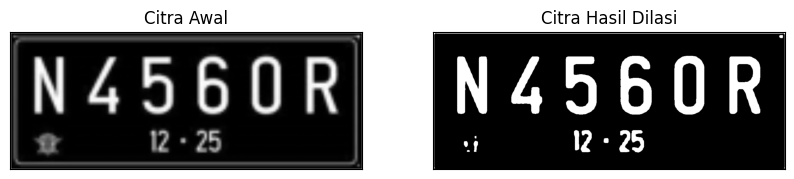

In [7]:
# Dilasi tanpa library
def dilasi_citra(F, w):
    # size image
    p, q = F.shape
    imgD = np.zeros((p, q), dtype=np.uint8)
    # Generate structure element dilasi (SED)
    SED = np.ones((w, w), dtype=np.uint8)
    constant1 = (w - 1) // 2
    # Proses Dilasi
    for i in range(constant1, p - constant1):
        for j in range(constant1, q - constant1):
            temp = F[i - constant1 : i + constant1 + 1, j - constant1 : j + constant1 + 1]
            product = temp * SED
            imgD[i, j] = np.max(product)
    return imgD

img_d = cv2.imread(BASE_PATH + 'plat nomer.jpg', 0)
ret, thresh = cv2.threshold(img_d, 125, 200, cv2.THRESH_BINARY)
w = 5
imgD = dilasi_citra(thresh, w)

plt.figure(figsize=(10, 5))
plt.subplot(121), plt.imshow(img_d, cmap='gray')
plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])
plt.subplot(122), plt.imshow(imgD, cmap='gray')
plt.title('Citra Hasil Dilasi'), plt.xticks([]), plt.yticks([])
plt.show()

### 4. Dilasi Menggunakan Library OpenCV (`cv2.dilate`)
Menggunakan Structuring Element $3\times3$ berbasis pustaka OpenCV.

[[1 1 1]
 [1 1 1]
 [1 1 1]]


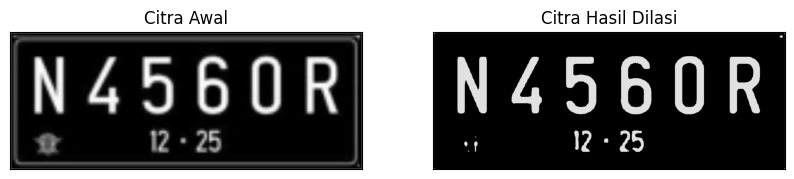

In [8]:
img = cv2.imread(BASE_PATH + 'plat nomer.jpg')
ret, thresh = cv2.threshold(img, 127, 225, cv2.THRESH_BINARY)
kernel = np.ones((3, 3), np.uint8)
dilasi = cv2.dilate(thresh, kernel, iterations=1)

print(kernel)
plt.figure(figsize=(10, 5))
plt.subplot(121), plt.imshow(img), plt.title('Citra Awal')
plt.xticks([]), plt.yticks([])
plt.subplot(122), plt.imshow(dilasi), plt.title('Citra Hasil Dilasi')
plt.xticks([]), plt.yticks([])
plt.show()

### 5. Erosi Tanpa Library OpenCV
Membuat fungsi `erosi_citra()` manual dengan Structuring Element Erosi (SE) Square $5\times5$.

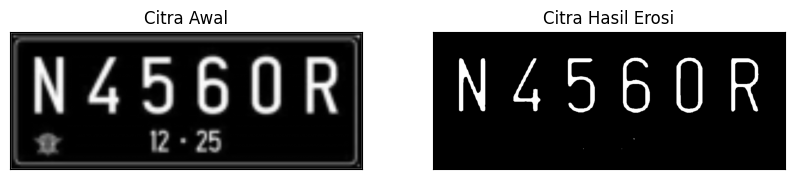

In [9]:
# Erosi Tanpa Library
def erosi_citra(F, k):
    # size image
    m, n = F.shape
    # Generate structure element erosi (SE)
    SE = np.ones((k, k), dtype=np.uint8)
    constant = (k - 1) // 2
    imgE = np.zeros((m, n), dtype=np.uint8)
    # Proses Erosi
    for i in range(constant, m - constant):
        for j in range(constant, n - constant):
            temp = F[i - constant : i + constant + 1, j - constant : j + constant + 1]
            product = temp * SE
            imgE[i, j] = np.min(product)
    return imgE

img_e = cv2.imread(BASE_PATH + 'plat nomer.jpg', 0)
ret1, thresh1 = cv2.threshold(img_e, 175, 225, cv2.THRESH_BINARY)
k = 5
imgE = erosi_citra(thresh1, k)

plt.figure(figsize=(10, 5))
plt.subplot(121), plt.imshow(img_e, cmap='gray')
plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])
plt.subplot(122), plt.imshow(imgE, cmap='gray')
plt.title('Citra Hasil Erosi'), plt.xticks([]), plt.yticks([])
plt.show()

### 6. Erosi Menggunakan Library OpenCV (`cv2.erode`)
Menerapkan operasi erosi menggunakan kernel square $5\times5$ bawaan OpenCV.

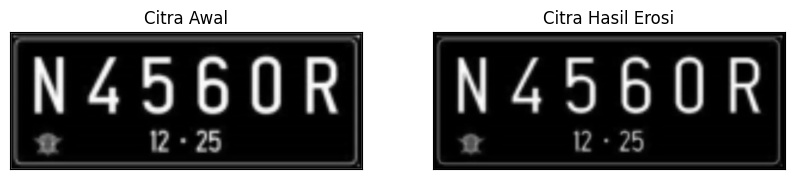

In [10]:
# EROSI LIBRARY
img = cv2.imread(BASE_PATH + 'plat nomer.jpg')
kernel = np.ones((5, 5), np.uint8)
erosion = cv2.erode(img, kernel, iterations=1)

plt.figure(figsize=(10, 5))
plt.subplot(121), plt.imshow(img), plt.title('Citra Awal')
plt.xticks([]), plt.yticks([])
plt.subplot(122), plt.imshow(erosion), plt.title('Citra Hasil Erosi')
plt.xticks([]), plt.yticks([])
plt.show()

### 7. Operasi Opening
Membandingkan proses **Opening** (Erosi dilanjutkan Dilasi) antara metode gabungan fungsi manual dan pustaka `cv2.morphologyEx(..., cv2.MORPH_OPEN)`.

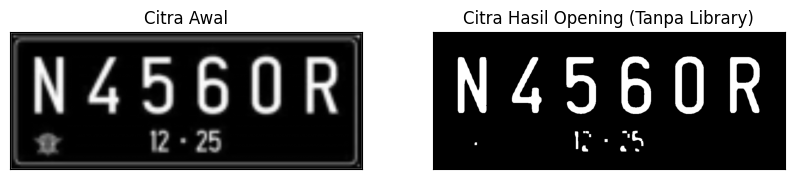

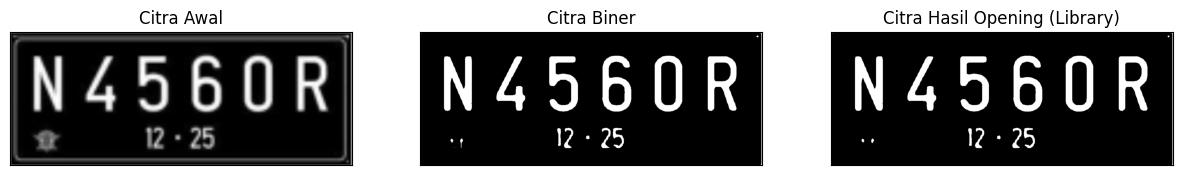

In [11]:
# Operasi Opening Menggunakan tanpa Library Morphology
img_o = cv2.imread(BASE_PATH + 'plat nomer.jpg', 0)
reto, thresho = cv2.threshold(img_o, 127, 225, cv2.THRESH_BINARY)
k = 7
imgO = dilasi_citra(erosi_citra(thresho, k), k)

plt.figure(figsize=(10, 5))
plt.subplot(121), plt.imshow(img_o, cmap='gray')
plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])
plt.subplot(122), plt.imshow(imgO, cmap='gray')
plt.title('Citra Hasil Opening (Tanpa Library)'), plt.xticks([]), plt.yticks([])
plt.show()

# Operasi Opening Menggunakan Library Morphology
img = cv2.imread(BASE_PATH + 'plat nomer.jpg', 0)
ret, thresh = cv2.threshold(img, 127, 225, cv2.THRESH_BINARY)
kernel = np.ones((3, 3), np.uint8)
openn = cv2.morphologyEx(thresh, cv2.MORPH_OPEN, kernel)

plt.figure(figsize=(15, 5))
plt.subplot(131), plt.imshow(img, cmap='gray')
plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])
plt.subplot(132), plt.imshow(thresh, cmap='gray')
plt.title('Citra Biner'), plt.xticks([]), plt.yticks([])
plt.subplot(133), plt.imshow(openn, cmap='gray')
plt.title('Citra Hasil Opening (Library)'), plt.xticks([]), plt.yticks([])
plt.show()

### 8. Operasi Closing
Membandingkan proses **Closing** (Dilasi dilanjutkan Erosi) antara metode manual dan pustaka `cv2.morphologyEx(..., cv2.MORPH_CLOSE)`.

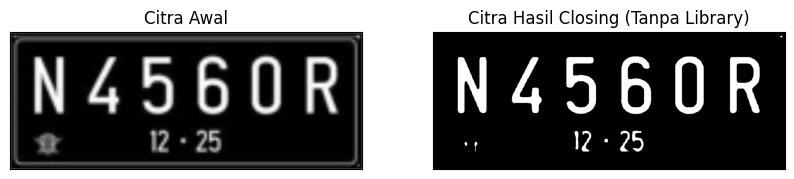

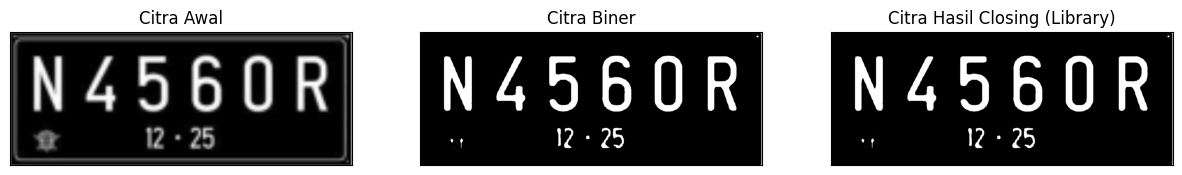

In [12]:
# operasi closing tanpa library morphology
img_c = cv2.imread(BASE_PATH + 'plat nomer.jpg', 0)
retc, threshc = cv2.threshold(img_c, 127, 225, cv2.THRESH_BINARY)
k = 7
imgC = erosi_citra(dilasi_citra(threshc, k), k)

plt.figure(figsize=(10, 5))
plt.subplot(121), plt.imshow(img_c, cmap='gray')
plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])
plt.subplot(122), plt.imshow(imgC, cmap='gray')
plt.title('Citra Hasil Closing (Tanpa Library)'), plt.xticks([]), plt.yticks([])
plt.show()

# operasi closing dengan library morphology
img = cv2.imread(BASE_PATH + 'plat nomer.jpg', 0)
ret, thresh = cv2.threshold(img, 127, 225, cv2.THRESH_BINARY)
kernel = np.ones((3, 3), np.uint8)
closs = cv2.morphologyEx(thresh, cv2.MORPH_CLOSE, kernel)

plt.figure(figsize=(15, 5))
plt.subplot(131), plt.imshow(img, cmap='gray')
plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])
plt.subplot(132), plt.imshow(thresh, cmap='gray')
plt.title('Citra Biner'), plt.xticks([]), plt.yticks([])
plt.subplot(133), plt.imshow(closs, cmap='gray')
plt.title('Citra Hasil Closing (Library)'), plt.xticks([]), plt.yticks([])
plt.show()

### 9. Dilasi dengan Cross Structuring Element ($3\times3$ dan $5\times5$)
Penggunaan bentuk matriks palang (*cross*) pada fungsi dilasi kustom.

SED = Cross 3


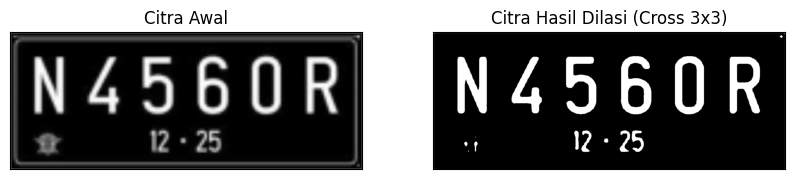

SED = Cross 5


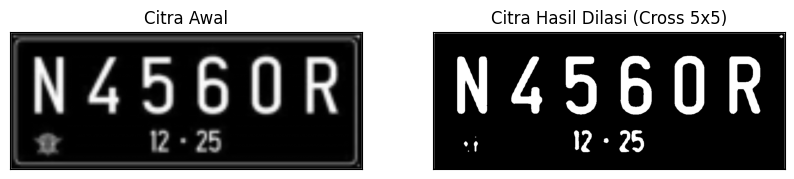

In [13]:
# Dilasi Cross SED 3x3
def dilasi_cross3(F, w):
    p, q = F.shape
    imgD = np.zeros((p, q), dtype=np.uint8)
    SED = np.array([[0, 1, 0],
                    [1, 1, 1],
                    [0, 1, 0]], dtype=np.uint8)
    constant1 = (w - 1) // 2
    for i in range(constant1, p - constant1):
        for j in range(constant1, q - constant1):
            temp = F[i - constant1 : i + constant1 + 1, j - constant1 : j + constant1 + 1]
            product = temp * SED
            imgD[i, j] = np.max(product)
    return imgD

print('SED = Cross 3')
img_d = cv2.imread(BASE_PATH + 'plat nomer.jpg', 0)
ret, thresh = cv2.threshold(img_d, 127, 225, cv2.THRESH_BINARY)
w = 3
imgD3 = dilasi_cross3(thresh, w)

plt.figure(figsize=(10, 5))
plt.subplot(121), plt.imshow(img_d, cmap='gray')
plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])
plt.subplot(122), plt.imshow(imgD3, cmap='gray')
plt.title('Citra Hasil Dilasi (Cross 3x3)'), plt.xticks([]), plt.yticks([])
plt.show()

# Dilasi Cross SED 5x5
def dilasi_cross5(F, w):
    p, q = F.shape
    imgD = np.zeros((p, q), dtype=np.uint8)
    SED = np.array([[0, 0, 1, 0, 0],
                    [0, 0, 1, 0, 0],
                    [1, 1, 1, 1, 1],
                    [0, 0, 1, 0, 0],
                    [0, 0, 1, 0, 0]], dtype=np.uint8)
    constant1 = (w - 1) // 2
    for i in range(constant1, p - constant1):
        for j in range(constant1, q - constant1):
            temp = F[i - constant1 : i + constant1 + 1, j - constant1 : j + constant1 + 1]
            product = temp * SED
            imgD[i, j] = np.max(product)
    return imgD

print('SED = Cross 5')
img_d = cv2.imread(BASE_PATH + 'plat nomer.jpg', 0)
ret, thresh = cv2.threshold(img_d, 127, 225, cv2.THRESH_BINARY)
w = 5
imgD5 = dilasi_cross5(thresh, w)

plt.figure(figsize=(10, 5))
plt.subplot(121), plt.imshow(img_d, cmap='gray')
plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])
plt.subplot(122), plt.imshow(imgD5, cmap='gray')
plt.title('Citra Hasil Dilasi (Cross 5x5)'), plt.xticks([]), plt.yticks([])
plt.show()

### 10. Dilasi dengan Circular Structuring Element ($3\times3$ dan $5\times5$)
Penggunaan kernel berbentuk lingkaran/elips (`cv2.MORPH_ELLIPSE`).

SED = Circle 3


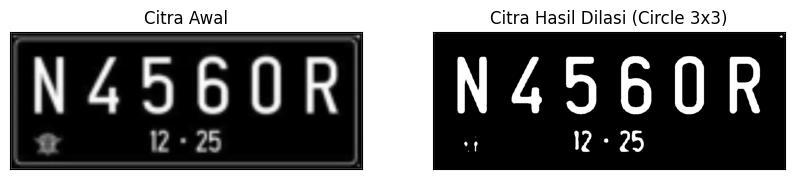

SED = Circle 5


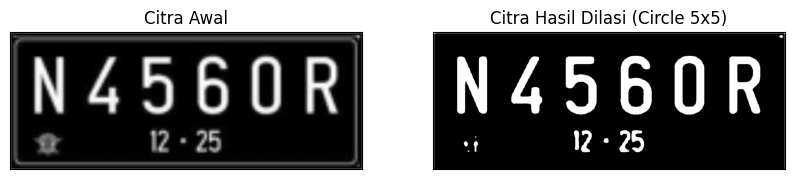

In [14]:
# Dilasi Circular SED
def dilasi_circular(F, w):
    p, q = F.shape
    imgD = np.zeros((p, q), dtype=np.uint8)
    SED = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (w, w))
    constant1 = (w - 1) // 2
    for i in range(constant1, p - constant1):
        for j in range(constant1, q - constant1):
            temp = F[i - constant1 : i + constant1 + 1, j - constant1 : j + constant1 + 1]
            product = temp * SED
            imgD[i, j] = np.max(product)
    return imgD

print('SED = Circle 3')
img_d = cv2.imread(BASE_PATH + 'plat nomer.jpg', 0)
ret, thresh = cv2.threshold(img_d, 127, 225, cv2.THRESH_BINARY)
w = 3
imgD_c3 = dilasi_circular(thresh, w)

plt.figure(figsize=(10, 5))
plt.subplot(121), plt.imshow(img_d, cmap='gray')
plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])
plt.subplot(122), plt.imshow(imgD_c3, cmap='gray')
plt.title('Citra Hasil Dilasi (Circle 3x3)'), plt.xticks([]), plt.yticks([])
plt.show()

print('SED = Circle 5')
img_d = cv2.imread(BASE_PATH + 'plat nomer.jpg', 0)
ret, thresh = cv2.threshold(img_d, 127, 225, cv2.THRESH_BINARY)
w = 5
imgD_c5 = dilasi_circular(thresh, w)

plt.figure(figsize=(10, 5))
plt.subplot(121), plt.imshow(img_d, cmap='gray')
plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])
plt.subplot(122), plt.imshow(imgD_c5, cmap='gray')
plt.title('Citra Hasil Dilasi (Circle 5x5)'), plt.xticks([]), plt.yticks([])
plt.show()

### 11. Erosi dengan Rectangle Structuring Element ($3\times5$ dan $5\times7$)
Menggunakan Structuring Element persegi panjang (`cv2.MORPH_RECT`).

SE = Rectangle 3x5


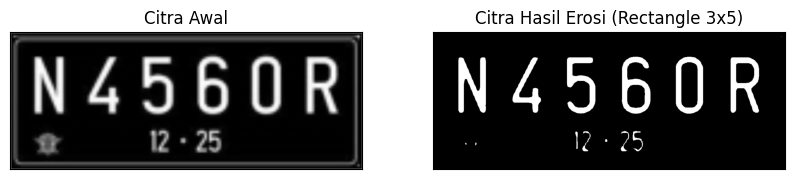

SE = Rectangle 5x7


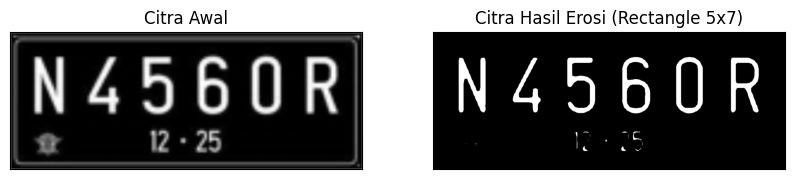

In [15]:
# Erosi Rectangle SE
def erosi_rectangle(F, p, l):
    m, n = F.shape
    SE = cv2.getStructuringElement(cv2.MORPH_RECT, (p, l))
    constant1 = (l - 1) // 2
    constant2 = (p - 1) // 2
    imgE = np.zeros((m, n), dtype=np.uint8)
    for i in range(constant1, m - constant1):
        for j in range(constant2, n - constant2):
            temp = F[i - constant1 : i + constant1 + 1, j - constant2 : j + constant2 + 1]
            product = temp * SE
            imgE[i, j] = np.min(product)
    return imgE

print('SE = Rectangle 3x5')
img_e = cv2.imread(BASE_PATH + 'plat nomer.jpg', 0)
ret1, thresh1 = cv2.threshold(img_e, 127, 225, cv2.THRESH_BINARY)
p = 5
l = 3
imgE_r35 = erosi_rectangle(thresh1, p, l)

plt.figure(figsize=(10, 5))
plt.subplot(121), plt.imshow(img_e, cmap='gray')
plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])
plt.subplot(122), plt.imshow(imgE_r35, cmap='gray')
plt.title('Citra Hasil Erosi (Rectangle 3x5)'), plt.xticks([]), plt.yticks([])
plt.show()

print('SE = Rectangle 5x7')
img_e = cv2.imread(BASE_PATH + 'plat nomer.jpg', 0)
ret1, thresh1 = cv2.threshold(img_e, 127, 225, cv2.THRESH_BINARY)
p = 7
l = 5
imgE_r57 = erosi_rectangle(thresh1, p, l)

plt.figure(figsize=(10, 5))
plt.subplot(121), plt.imshow(img_e, cmap='gray')
plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])
plt.subplot(122), plt.imshow(imgE_r57, cmap='gray')
plt.title('Citra Hasil Erosi (Rectangle 5x7)'), plt.xticks([]), plt.yticks([])
plt.show()

### 12. Erosi dengan Line Vertikal Structuring Element ($k=3$ dan $k=5$)
Penggunaan elemen garis tegak berukuran 3 dan 5 piksel.

SE Line Vertikal 3


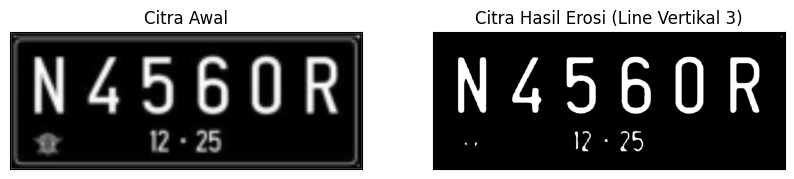

SE Line Vertikal 5


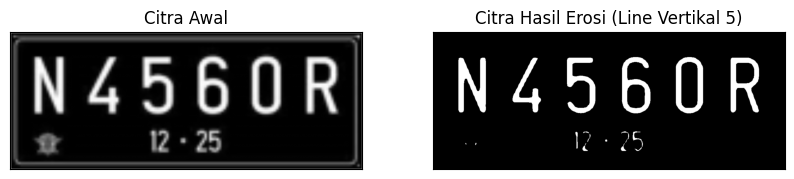

In [16]:
# Erosi Line Vertikal SE
def erosi_line_vertikal(F, k):
    m, n = F.shape
    SE = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (1, k))
    constant = (k - 1) // 2
    imgE = np.zeros((m, n), dtype=np.uint8)
    for i in range(constant, m - constant):
        for j in range(constant, n - constant):
            temp = F[i - constant : i + constant + 1, j - constant : j + constant + 1]
            product = temp * SE
            imgE[i, j] = np.min(product)
    return imgE

print('SE Line Vertikal 3')
img_e = cv2.imread(BASE_PATH + 'plat nomer.jpg', 0)
ret1, thresh1 = cv2.threshold(img_e, 127, 225, cv2.THRESH_BINARY)
k = 3
imgE_v3 = erosi_line_vertikal(thresh1, k)

plt.figure(figsize=(10, 5))
plt.subplot(121), plt.imshow(img_e, cmap='gray')
plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])
plt.subplot(122), plt.imshow(imgE_v3, cmap='gray')
plt.title('Citra Hasil Erosi (Line Vertikal 3)'), plt.xticks([]), plt.yticks([])
plt.show()

print('SE Line Vertikal 5')
img_e = cv2.imread(BASE_PATH + 'plat nomer.jpg', 0)
ret1, thresh1 = cv2.threshold(img_e, 127, 225, cv2.THRESH_BINARY)
k = 5
imgE_v5 = erosi_line_vertikal(thresh1, k)

plt.figure(figsize=(10, 5))
plt.subplot(121), plt.imshow(img_e, cmap='gray')
plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])
plt.subplot(122), plt.imshow(imgE_v5, cmap='gray')
plt.title('Citra Hasil Erosi (Line Vertikal 5)'), plt.xticks([]), plt.yticks([])
plt.show()

### 13 & 14. Transformasi Top-Hat dan Black-Hat
- **Top-Hat ($f - \gamma(f)$):** Menonjolkan elemen terang yang lebih kecil dari Structuring Element.
- **Black-Hat ($\phi(f) - f$):** Menonjolkan elemen gelap yang lebih kecil dari Structuring Element (Diuji pada `kitten01.jpg`).

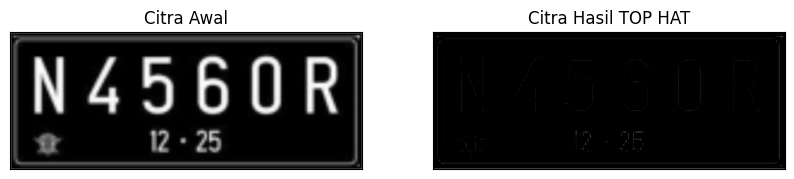

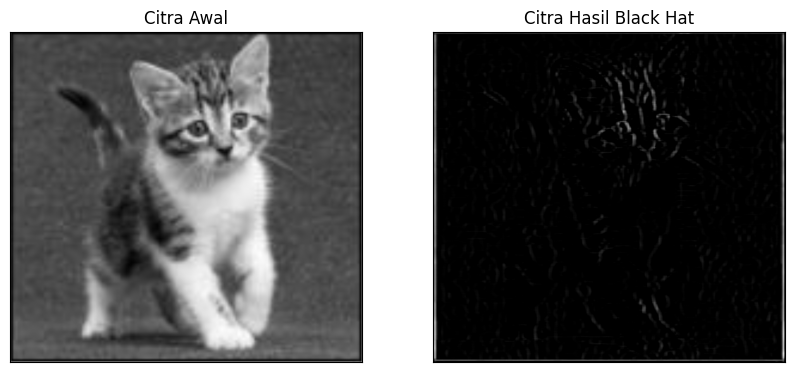

In [17]:
# 13. Top-Hat Operation
filterSize = (3, 3)
kernel = cv2.getStructuringElement(cv2.MORPH_RECT, filterSize)

img_top = cv2.imread(BASE_PATH + 'plat nomer.jpg')
img_top_gray = cv2.cvtColor(img_top, cv2.COLOR_BGR2GRAY)
tophat_img = cv2.morphologyEx(img_top_gray, cv2.MORPH_TOPHAT, kernel)

plt.figure(figsize=(10, 5))
plt.subplot(121), plt.imshow(img_top_gray, cmap='gray')
plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])
plt.subplot(122), plt.imshow(tophat_img, cmap='gray')
plt.title('Citra Hasil TOP HAT'), plt.xticks([]), plt.yticks([])
plt.show()

# 14. Black-Hat Operation
img_black = cv2.imread(BASE_PATH + 'kitten01.jpg')
if img_black is not None:
    img_black_gray = cv2.cvtColor(img_black, cv2.COLOR_BGR2GRAY)
    kernel_bh = cv2.getStructuringElement(cv2.MORPH_RECT, (13, 5))
    blackhat_img = cv2.morphologyEx(img_black_gray, cv2.MORPH_BLACKHAT, kernel_bh)

    plt.figure(figsize=(10, 5))
    plt.subplot(121), plt.imshow(img_black_gray, cmap='gray')
    plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])
    plt.subplot(122), plt.imshow(blackhat_img, cmap='gray')
    plt.title('Citra Hasil Black Hat'), plt.xticks([]), plt.yticks([])
    plt.show()

### 15 & 16. Skeleton dan Skeleton Inverse
Ekstraksi kerangka objek dari citra `lily.jpg` menggunakan modul `skimage.morphology.skeletonize`.

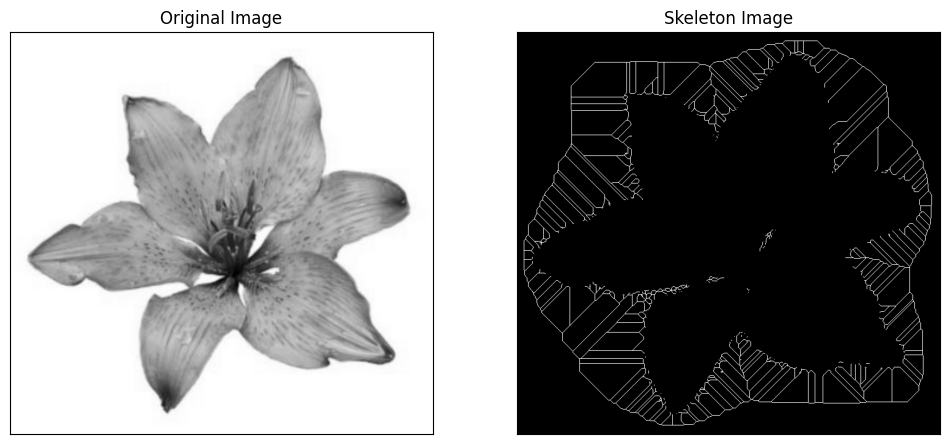

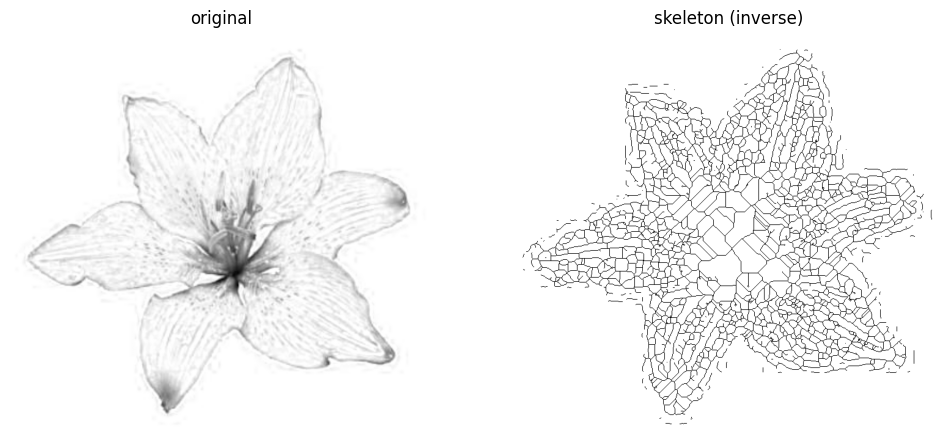

In [18]:
from skimage import filters, io
from skimage.morphology import skeletonize

# 15. Skeleton
img_lily = cv2.imread(BASE_PATH + 'lily.jpg', 0)
if img_lily is not None:
    binary = img_lily > filters.threshold_triangle(img_lily)

    binary_cp = binary.copy()
    binary_cp[binary_cp == True] = 1
    binary_cp[binary_cp == False] = 0

    skeleton = skeletonize(binary_cp)

    plt.figure(figsize=(12, 6))
    plt.subplot(121), plt.imshow(img_lily, cmap='gray')
    plt.title('Original Image'), plt.xticks([]), plt.yticks([])
    plt.subplot(122), plt.imshow(skeleton, cmap='gray')
    plt.title('Skeleton Image'), plt.xticks([]), plt.yticks([])
    plt.savefig("binary_and_bin_skeleton.png")
    plt.show()

# 16. Skeleton Inverse
img_lily_inv = io.imread(BASE_PATH + 'lily.jpg')[..., 0]
binary_inv = img_lily_inv < filters.threshold_triangle(img_lily_inv)
skeleton_inv = skeletonize(binary_inv)

fig, ax = plt.subplots(1, 2, figsize=(12, 6))
ax[0].imshow(img_lily_inv, cmap='gray')
ax[0].set_title('original')
ax[0].axis('off')

ax[1].imshow(skeleton_inv, cmap='gray_r')
ax[1].set_title('skeleton (inverse)')
ax[1].axis('off')
plt.show()

### 17. Thinning (Penipisan Citra)
Proses penipisan citra biner menggunakan fungsi `skimage.morphology.thin`.

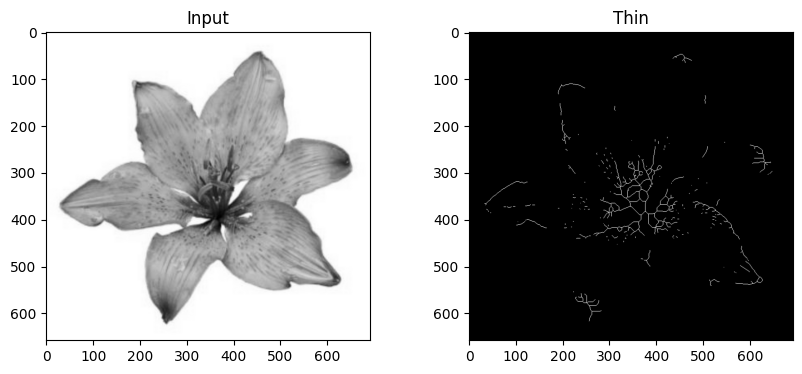

In [21]:
import cv2 as cv
from skimage import img_as_float, morphology
import matplotlib.pyplot as plt

# 1. Baca langsung sebagai Grayscale menggunakan OpenCV
img_gray = cv.imread(BASE_PATH + 'lily.jpg', cv.IMREAD_GRAYSCALE)

# 2. Konversi ke float [0, 1]
image_lily = img_as_float(img_gray)
image_binary = image_lily < 0.5
out_skeletonize = morphology.skeletonize(image_binary)
out_thin = morphology.thin(image_binary)

f, (ax0, ax1) = plt.subplots(1, 2, figsize=(10, 4))
ax0.imshow(image_lily, cmap='gray')
ax0.set_title('Input')
ax1.imshow(out_thin, cmap='gray')
ax1.set_title('Thin')
plt.savefig('/tmp/char_out.png')
plt.show()

---
## E. TUGAS PRAKTIKUM (KTP MORPHOLOGY ENHANCEMENT)

Penerapan kombinasi operasi morfologi (Closing / Opening / Dilation) pada dataset citra **KTP** (`ktp_fulan.jpg` dari Modul 7) untuk membersihkan noise latar belakang dan mempertegas karakter teks KTP.

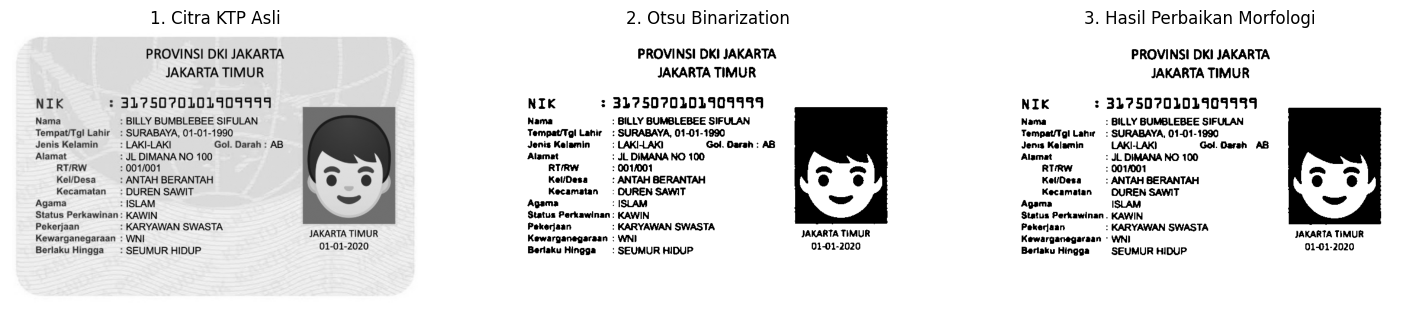

In [20]:
# Tugas Praktikum Morfologi pada Citra KTP
img_ktp = cv2.imread(BASE_PATH + 'ktp_fulan.jpg', 0)

if img_ktp is not None:
    # 1. Binerisasi Citra KTP dengan Otsu Thresholding
    blur_ktp = cv2.GaussianBlur(img_ktp, (3, 3), 0)
    ret_ktp, thresh_ktp = cv2.threshold(blur_ktp, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)

    # 2. Operasi Closing untuk Menyambung Karakter Teks yang Terputus
    kernel_ktp_close = cv2.getStructuringElement(cv2.MORPH_RECT, (2, 2))
    ktp_closed = cv2.morphologyEx(thresh_ktp, cv2.MORPH_CLOSE, kernel_ktp_close)

    # 3. Operasi Opening untuk Penghilangan Bintik Noise Kecil pada Background
    kernel_ktp_open = cv2.getStructuringElement(cv2.MORPH_RECT, (1, 1))
    ktp_enhanced = cv2.morphologyEx(ktp_closed, cv2.MORPH_OPEN, kernel_ktp_open)

    # Visualisasi Komparasi
    plt.figure(figsize=(18, 6))
    plt.subplot(131), plt.imshow(img_ktp, cmap='gray')
    plt.title('1. Citra KTP Asli'), plt.axis('off')

    plt.subplot(132), plt.imshow(thresh_ktp, cmap='gray')
    plt.title('2. Otsu Binarization'), plt.axis('off')

    plt.subplot(133), plt.imshow(ktp_enhanced, cmap='gray')
    plt.title('3. Hasil Perbaikan Morfologi'), plt.axis('off')
    plt.show()
else:
    print("File ktp_fulan.jpg tidak ditemukan pada path:", BASE_PATH)